In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os
import random
import re
from datetime import datetime
from datetime import date
from pathlib import Path

In [2]:
now = datetime.now().strftime("%Y-%m-%d_%H%M%S")

LA1 = f"/data/icecores/Output/AN/ALHIC/ALHIC1901/ALHIC1901-228_4-LA1/2025-12-18_220420/bubbles_per_cm.csv"
LA2 = f"/data/icecores/Output/AN/ALHIC/ALHIC1901/ALHIC1901-228_4-LA2/2025-12-18_220258/bubbles_per_cm.csv"
LA3 = f"/data/icecores/Output/AN/ALHIC/ALHIC1901/ALHIC1901-228_4-LA3/2025-12-18_215933/bubbles_per_cm.csv"
LA4 = f"/data/icecores/Output/AN/ALHIC/ALHIC1901/ALHIC1901-228_4-LA4/2025-12-18_215314/bubbles_per_cm.csv"
LA5 = f"/data/icecores/Output/AN/ALHIC/ALHIC1901/ALHIC1901-228_4-LA5/2025-12-18_215039/bubbles_per_cm.csv"
LA6 = f"/data/icecores/Output/AN/ALHIC/ALHIC1901/ALHIC1901-228_4-LA6/2025-12-18_214622/bubbles_per_cm.csv"

LA1_df = pd.read_csv(LA1)
LA2_df = pd.read_csv(LA2)
LA3_df = pd.read_csv(LA3)
LA4_df = pd.read_csv(LA4)
LA5_df = pd.read_csv(LA5)
LA6_df = pd.read_csv(LA6)
output_dir = Path(f"/data/icecores/Output/AN/ALHIC/ALHIC1901/ALHIC1901-228/{now}")
output_dir.mkdir(parents=True, exist_ok=False) 

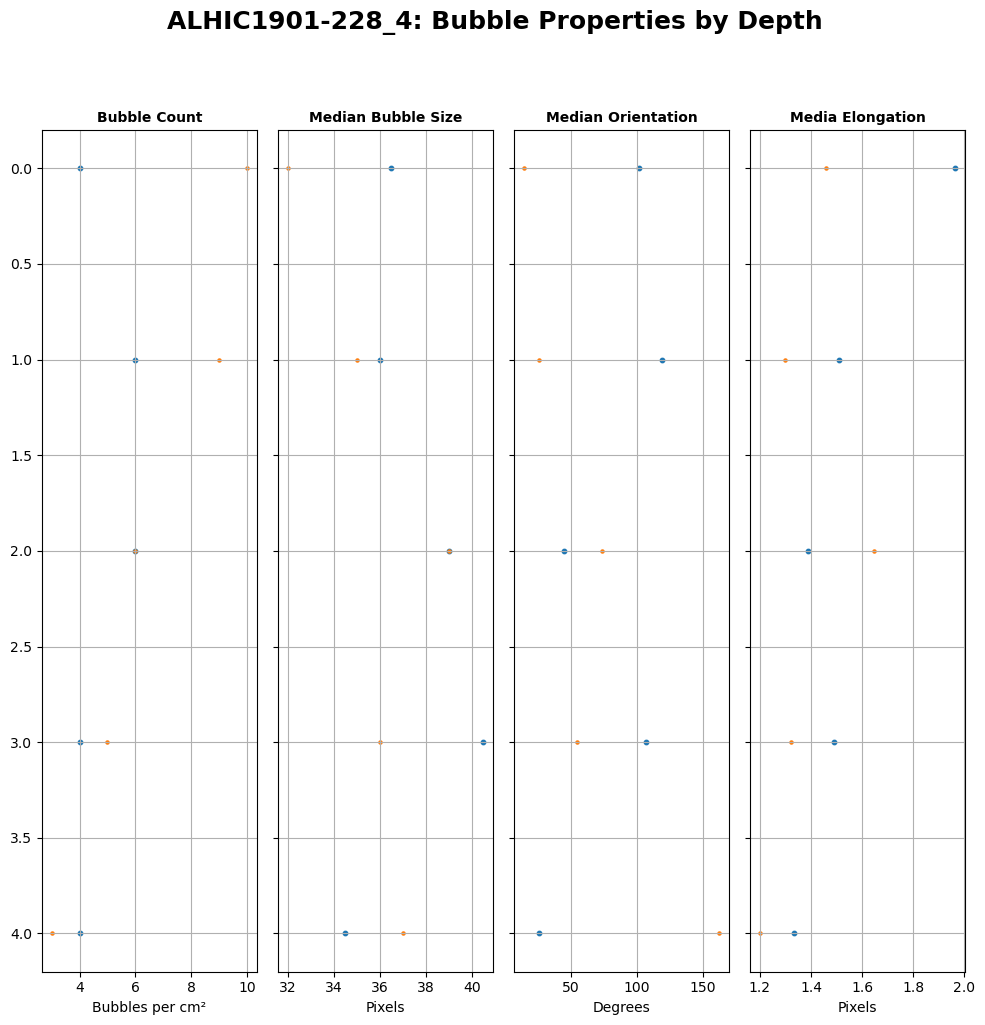

In [6]:
LA1x_df = LA1_df.copy()
LA6x_df = LA6_df.copy()


plot_vars = [
    ("Bubble_Count", "Bubble Count", "Bubbles per cm²"),
    ("Median_Bubble_Size", "Median Bubble Size", "Pixels"),
    ("Median_Orientation", "Median Orientation", "Degrees"),
    ("Median_Elongation", "Media Elongation", "Pixels")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label, xlabel) in zip(axes, plot_vars):
    ax.scatter(LA1x_df[var], LA1x_df.index, s=10)
    ax.scatter(LA6x_df[var], LA6x_df.index, s=5)
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    ax.set_xlabel(f"{xlabel}")

# === Set common y-axis label ===
# axes[0].set_ylabel("Depth (m)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
plt.suptitle("ALHIC1901-228_4: Bubble Properties by Depth", y=1.02, fontsize=18, fontweight='bold')
plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleGraph.png", dpi=300, bbox_inches='tight')
plt.show()

In [7]:
df1_list = [LA1_df, LA3_df, LA5_df]
df2_list = [LA2_df, LA4_df, LA6_df]
combined1 = pd.concat(df1_list, ignore_index=True)
combined2 = pd.concat(df2_list, ignore_index=True)

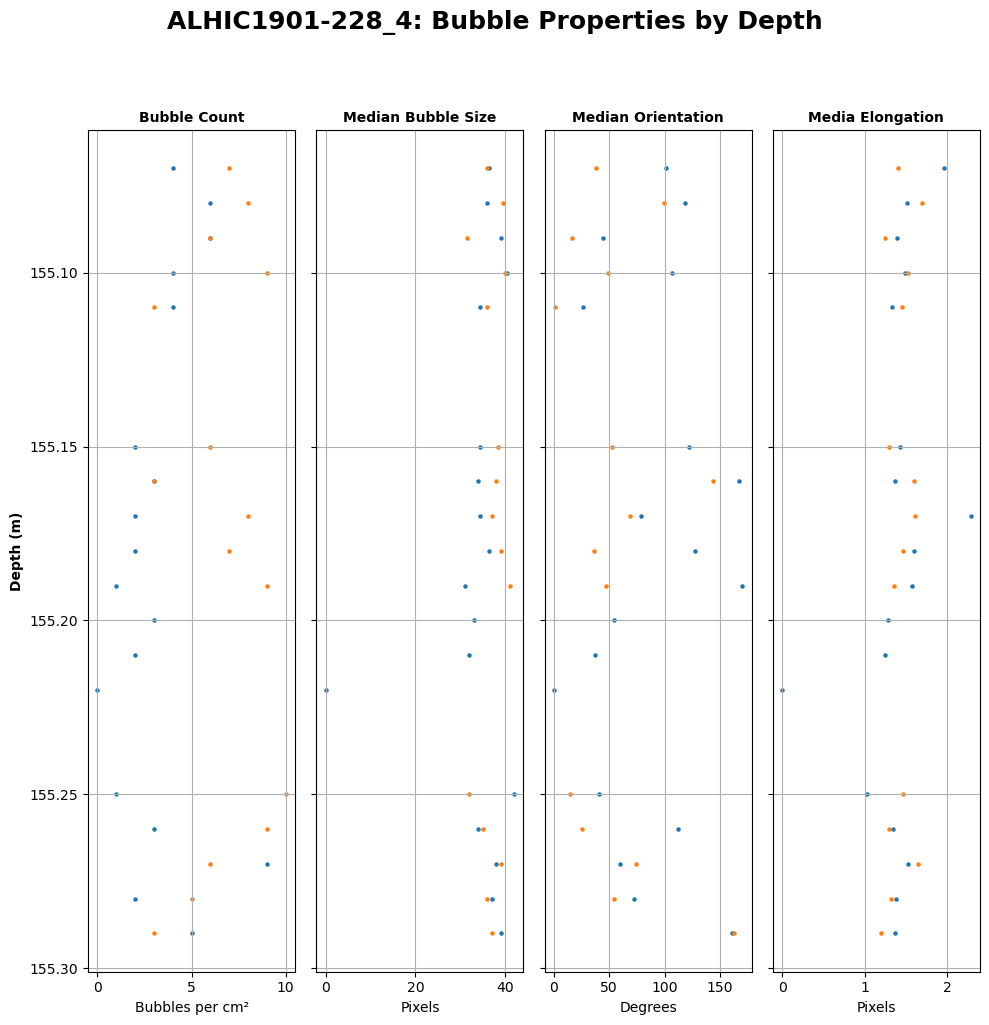

In [8]:
dfx1 = combined1.copy()
dfx1['Depth_cm'] = dfx1['Depth_cm'] / 100
dfx2 = combined2.copy()
dfx2['Depth_cm'] = dfx2['Depth_cm'] / 100

plot_vars = [
    ("Bubble_Count", "Bubble Count", "Bubbles per cm²"),
    ("Median_Bubble_Size", "Median Bubble Size", "Pixels"),
    ("Median_Orientation", "Median Orientation", "Degrees"),
    ("Median_Elongation", "Media Elongation", "Pixels")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label, xlabel) in zip(axes, plot_vars):
    ax.scatter(dfx1[var], dfx1["Depth_cm"], s=5)
    ax.scatter(dfx2[var], dfx2["Depth_cm"], s=5)
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    ax.set_xlabel(f"{xlabel}")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (m)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
plt.suptitle("ALHIC1901-228_4: Bubble Properties by Depth", y=1.02, fontsize=18, fontweight='bold')
plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleGraph.png", dpi=300, bbox_inches='tight')
plt.show()